In [1]:
# --- Section 1: Setup, config & GPU check ---
import os, numpy as np, pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

RANDOM_STATE = 42
tf.random.set_seed(RANDOM_STATE); np.random.seed(RANDOM_STATE)

TARGET_CLASSES = ['angry', 'happy', 'sad', 'neutral']
IMG_SIZE = 96          # we resize the 48x48 faces up to 96x96 for the pretrained model
BATCH    = 64
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow version:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print("✅ GPU is ON:", gpus[0].name)
else:
    print("❌ No GPU! Go to Runtime > Change runtime type > T4 GPU, then re-run.")

TensorFlow version: 2.21.0
✅ GPU is ON: /physical_device:GPU:0


In [2]:
# --- Section 2a: Download fer2013.csv (pixels) ---
from google.colab import files
print("Upload your kaggle.json again (same file as before)...")
files.upload()
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d deadskull7/fer2013 -q
!unzip -q -o fer2013.zip -d fer2013_csv

import glob
csvs = glob.glob('fer2013_csv/**/*.csv', recursive=True)
FER_CSV = next((c for c in csvs if c.endswith('fer2013.csv')), csvs[0] if csvs else None)
print("CSV files found:", csvs)
print("Using:", FER_CSV)

Upload your kaggle.json again (same file as before)...


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/deadskull7/fer2013
License(s): CC0-1.0
CSV files found: ['fer2013_csv/fer2013.csv']
Using: fer2013_csv/fer2013.csv


In [4]:
# --- Section 2b: Download FER+ labels (robust, verified) ---
import urllib.request, os

urls = [
    "https://raw.githubusercontent.com/microsoft/FERPlus/master/fer2013new.csv",
    "https://raw.githubusercontent.com/microsoft/FERPlus/main/fer2013new.csv",
    "https://media.githubusercontent.com/media/microsoft/FERPlus/master/fer2013new.csv",
]
ok = False
for u in urls:
    try:
        urllib.request.urlretrieve(u, "fer2013new.csv")
        size = os.path.getsize("fer2013new.csv")
        head = open("fer2013new.csv").read(200)
        if size > 10000 and not head.lstrip().startswith("<"):   # not a 404 HTML page
            print("✅ Downloaded from:", u, "| size:", size, "bytes")
            ok = True
            break
        print("✗ Bad/empty file from:", u, "(size", size, ")")
    except Exception as e:
        print("✗ Failed:", u, "->", e)

assert ok, "Could not download fer2013new.csv — tell me and we'll use another source."

✅ Downloaded from: https://raw.githubusercontent.com/microsoft/FERPlus/master/fer2013new.csv | size: 1602762 bytes


In [5]:
# --- Section 2c: Load & verify alignment ---
fer     = pd.read_csv(FER_CSV)          # columns: emotion, pixels, Usage
ferplus = pd.read_csv('fer2013new.csv') # columns: Usage, Image name, + 10 vote columns

print("fer2013 :", fer.shape, "->", list(fer.columns))
print("fer+    :", ferplus.shape, "->", list(ferplus.columns))

assert len(fer) == len(ferplus), "Row counts differ - alignment would break!"
print("Usage columns match row-by-row:", (fer['Usage'].values == ferplus['Usage'].values).all())

fer2013 : (35887, 3) -> ['emotion', 'pixels', 'Usage']
fer+    : (35887, 12) -> ['Usage', 'Image name', 'neutral', 'happiness', 'surprise', 'sadness', 'anger', 'disgust', 'fear', 'contempt', 'unknown', 'NF']
Usage columns match row-by-row: True


In [6]:
# --- Section 3a: Build clean 4-class FER+ dataset ---
vote_cols = ['neutral','happiness','surprise','sadness','anger',
             'disgust','fear','contempt','unknown','NF']

# FER+ emotion -> our class index (TARGET_CLASSES = ['angry','happy','sad','neutral'])
ferplus_to_label = {'anger': 0, 'happiness': 1, 'sadness': 2, 'neutral': 3}

winner_name = np.array(vote_cols)[ferplus[vote_cols].values.argmax(axis=1)]  # majority vote
keep   = np.array([w in ferplus_to_label for w in winner_name])             # only our 4 classes
labels = np.array([ferplus_to_label.get(w, -1) for w in winner_name])

print("Total faces:", len(fer), "| kept (our 4 classes):", keep.sum())

def pixels_to_img(s):
    return np.array(s.split(), dtype='uint8').reshape(48, 48)

usage = fer['Usage'].values
def build_split(name):
    idx = np.where(keep & (usage == name))[0]
    X = np.stack([pixels_to_img(fer['pixels'].iloc[i]) for i in idx])
    return X, labels[idx]

X_train, y_train = build_split('Training')
X_val,   y_val   = build_split('PublicTest')
X_test,  y_test  = build_split('PrivateTest')
print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)

Total faces: 35887 | kept (our 4 classes): 29743
Train: (23819, 48, 48) | Val: (2965, 48, 48) | Test: (2959, 48, 48)


In [7]:
# --- Section 3b: Class distribution ---
names = {0:'angry', 1:'happy', 2:'sad', 3:'neutral'}
print("Train class counts:")
print(pd.Series(y_train).map(names).value_counts())
assert set(np.unique(y_train)) == {0,1,2,3}, "A class is missing!"
print("All 4 classes present ✓")

Train class counts:
neutral    10309
happy       7528
sad         3515
angry       2467
Name: count, dtype: int64
All 4 classes present ✓


In [8]:
# --- Section 4a: tf.data pipelines (resize -> RGB) ---
def to_rgb96(img, label):
    img = tf.cast(img, tf.float32)
    img = tf.expand_dims(img, -1)                      # (48,48,1)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])   # (96,96,1)
    img = tf.image.grayscale_to_rgb(img)               # (96,96,3), still 0-255
    return img, label

def make_ds(X, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(4000, seed=RANDOM_STATE)
    ds = ds.map(to_rgb96, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(X_train, y_train, training=True)
val_ds   = make_ds(X_val,   y_val)
test_ds  = make_ds(X_test,  y_test)

for imgs, labs in train_ds.take(1):
    print("Batch:", imgs.shape, imgs.dtype, "| pixel range:",
          float(tf.reduce_min(imgs)), "to", float(tf.reduce_max(imgs)))

Batch: (64, 96, 96, 3) <dtype: 'float32'> | pixel range: 0.0 to 255.0


In [9]:
# --- Section 4b: Class weights ---
from sklearn.utils.class_weight import compute_class_weight
names = {0:'angry', 1:'happy', 2:'sad', 3:'neutral'}
cw = compute_class_weight('balanced', classes=np.array([0,1,2,3]), y=y_train)
class_weight = {i: float(w) for i, w in enumerate(cw)}
print("Class weights:", {names[i]: round(class_weight[i], 2) for i in range(4)})

Class weights: {'angry': 2.41, 'happy': 0.79, 'sad': 1.69, 'neutral': 0.58}


In [10]:
# --- Section 5: Build the transfer-learning model ---
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10),
], name='augment')

base = MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
base.trainable = False      # Phase 1: freeze the pretrained body

inputs  = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(1./127.5, offset=-1)(x)        # the preprocessing MobileNetV2 expects
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)                           # reduces overfitting
outputs = layers.Dense(len(TARGET_CLASSES), activation='softmax')(x)

model = models.Model(inputs, outputs)
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [11]:
# --- Section 6: Phase 1 training (frozen base) ---
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1),
    ModelCheckpoint('best.keras', monitor='val_accuracy', save_best_only=True),
]

history1 = model.fit(train_ds, validation_data=val_ds,
                     epochs=12, class_weight=class_weight, callbacks=callbacks)

Epoch 1/12
373/373 ━━━━━━━━━━━━━━━━━━━━ 23s 38ms/step - accuracy: 0.4129 - loss: 1.4223 - val_accuracy: 0.4590 - val_loss: 1.2398 - learning_rate: 0.0010
Epoch 2/12
373/373 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.4892 - loss: 1.2068 - val_accuracy: 0.5295 - val_loss: 1.1113 - learning_rate: 0.0010
Epoch 3/12
373/373 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.5071 - loss: 1.1562 - val_accuracy: 0.5616 - val_loss: 1.0609 - learning_rate: 0.0010
Epoch 4/12
373/373 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.5092 - loss: 1.1606 - val_accuracy: 0.5562 - val_loss: 1.0569 - learning_rate: 0.0010
Epoch 5/12
373/373 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - accuracy: 0.5125 - loss: 1.1495 - val_accuracy: 0.5477 - val_loss: 1.0685 - learning_rate: 0.0010
Epoch 6/12
372/373 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.5226 - loss: 1.1380
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
373/373 ━━━━━━━━━━━━━━━━━━━━ 13s 35ms/step - accuracy: 0.5192 - los

In [12]:
# --- Section 7: Phase 2 fine-tuning (unfreeze top layers) ---
base.trainable = True
for layer in base.layers[:100]:      # keep the bottom frozen, fine-tune the top ~54 layers
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),   # low LR for gentle fine-tuning
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

print("Trainable layers now:", sum(l.trainable for l in base.layers), "of", len(base.layers))

history2 = model.fit(train_ds, validation_data=val_ds,
                     epochs=15, class_weight=class_weight, callbacks=callbacks)

Trainable layers now: 54 of 154
Epoch 1/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 41s 67ms/step - accuracy: 0.5468 - loss: 1.1561 - val_accuracy: 0.6054 - val_loss: 1.1596 - learning_rate: 1.0000e-04
Epoch 2/15
372/373 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.6367 - loss: 0.8714
Epoch 2: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
373/373 ━━━━━━━━━━━━━━━━━━━━ 24s 63ms/step - accuracy: 0.6539 - loss: 0.8386 - val_accuracy: 0.6256 - val_loss: 1.2598 - learning_rate: 1.0000e-04
Epoch 3/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 23s 63ms/step - accuracy: 0.7007 - loss: 0.7228 - val_accuracy: 0.6863 - val_loss: 0.9027 - learning_rate: 5.0000e-05
Epoch 4/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 23s 62ms/step - accuracy: 0.7126 - loss: 0.6810 - val_accuracy: 0.7015 - val_loss: 0.8582 - learning_rate: 5.0000e-05
Epoch 5/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 24s 65ms/step - accuracy: 0.7302 - loss: 0.6339 - val_accuracy: 0.7315 - val_loss: 0.7345 - learning_rate: 5.0000e-05
Epoch 6/15
373/373 ━━━━━━━

In [13]:
# --- Plan B: native 48x48 grayscale pipeline ---
def to_cnn(img, label):
    img = tf.cast(img, tf.float32) / 255.0
    return tf.expand_dims(img, -1), label        # (48,48,1)

def make_cnn_ds(X, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training: ds = ds.shuffle(4000, seed=RANDOM_STATE)
    return ds.map(to_cnn, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

train_ds2 = make_cnn_ds(X_train, y_train, training=True)
val_ds2   = make_cnn_ds(X_val,   y_val)
test_ds2  = make_cnn_ds(X_test,  y_test)
print("CNN pipelines ready.")

CNN pipelines ready.


In [14]:
# --- Plan B: purpose-built CNN ---
aug = tf.keras.Sequential([layers.RandomFlip('horizontal'),
                           layers.RandomRotation(0.1),
                           layers.RandomZoom(0.1)], name='aug')
inp = layers.Input((48,48,1))
x = aug(inp)
for f in [64, 128, 256]:
    x = layers.Conv2D(f, 3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(f, 3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.3)(x)
x = layers.Flatten()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.5)(x)
out = layers.Dense(4, activation='softmax')(x)
cnn = models.Model(inp, out)
cnn.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
            loss='sparse_categorical_crossentropy', metrics=['accuracy'])
print("Params:", cnn.count_params())

Params: 3509444


In [15]:
# --- Plan B: train ---
cb = [tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True),
      tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, verbose=1),
      tf.keras.callbacks.ModelCheckpoint('best_cnn.keras', monitor='val_accuracy', save_best_only=True)]
hist = cnn.fit(train_ds2, validation_data=val_ds2, epochs=60,
               class_weight=class_weight, callbacks=cb)
print("Best val_accuracy:", max(hist.history['val_accuracy']))

Epoch 1/60
373/373 ━━━━━━━━━━━━━━━━━━━━ 33s 67ms/step - accuracy: 0.3225 - loss: 1.6389 - val_accuracy: 0.4921 - val_loss: 1.2073 - learning_rate: 0.0010
Epoch 2/60
373/373 ━━━━━━━━━━━━━━━━━━━━ 24s 64ms/step - accuracy: 0.4588 - loss: 1.2691 - val_accuracy: 0.4263 - val_loss: 1.2240 - learning_rate: 0.0010
Epoch 3/60
373/373 ━━━━━━━━━━━━━━━━━━━━ 24s 65ms/step - accuracy: 0.5590 - loss: 1.0420 - val_accuracy: 0.5329 - val_loss: 1.1128 - learning_rate: 0.0010
Epoch 4/60
373/373 ━━━━━━━━━━━━━━━━━━━━ 25s 66ms/step - accuracy: 0.6270 - loss: 0.8981 - val_accuracy: 0.5720 - val_loss: 1.0136 - learning_rate: 0.0010
Epoch 5/60
373/373 ━━━━━━━━━━━━━━━━━━━━ 25s 67ms/step - accuracy: 0.6567 - loss: 0.8237 - val_accuracy: 0.6968 - val_loss: 0.7367 - learning_rate: 0.0010
Epoch 6/60
373/373 ━━━━━━━━━━━━━━━━━━━━ 24s 65ms/step - accuracy: 0.6869 - loss: 0.7655 - val_accuracy: 0.7376 - val_loss: 0.6693 - learning_rate: 0.0010
Epoch 7/60
373/373 ━━━━━━━━━━━━━━━━━━━━ 24s 63ms/step - accuracy: 0.7005 - l

In [16]:
# --- Section 8a: Test-set evaluation ---
test_loss, test_acc = cnn.evaluate(test_ds2, verbose=0)
print(f"Plain test accuracy: {test_acc:.4f}")

Plain test accuracy: 0.8175


In [17]:
# --- Section 8b: TTA ---
Xte = (X_test.astype('float32')/255.0)[..., None]          # (N,48,48,1)
p1 = cnn.predict(Xte, batch_size=128, verbose=0)
p2 = cnn.predict(Xte[:, :, ::-1, :], batch_size=128, verbose=0)  # horizontal flip
proba  = (p1 + p2) / 2
y_pred = proba.argmax(1)
print(f"TTA test accuracy: {(y_pred == y_test).mean():.4f}")

TTA test accuracy: 0.8273


              precision    recall  f1-score   support

       angry       0.69      0.89      0.78       325
       happy       0.95      0.92      0.93       928
         sad       0.60      0.76      0.67       444
     neutral       0.90      0.77      0.83      1262

    accuracy                           0.83      2959
   macro avg       0.78      0.83      0.80      2959
weighted avg       0.85      0.83      0.83      2959



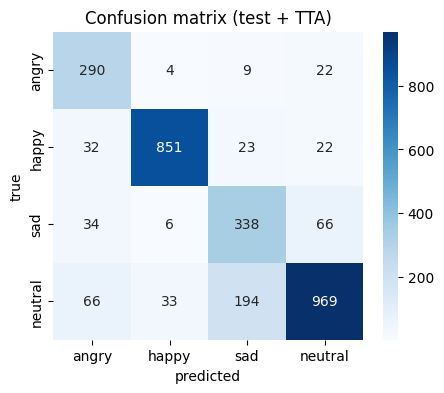

In [18]:
# --- Section 8c: Detailed report ---
print(classification_report(y_test, y_pred, target_names=TARGET_CLASSES))
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=TARGET_CLASSES,
            yticklabels=TARGET_CLASSES, cmap='Blues')
plt.xlabel('predicted'); plt.ylabel('true'); plt.title('Confusion matrix (test + TTA)'); plt.show()

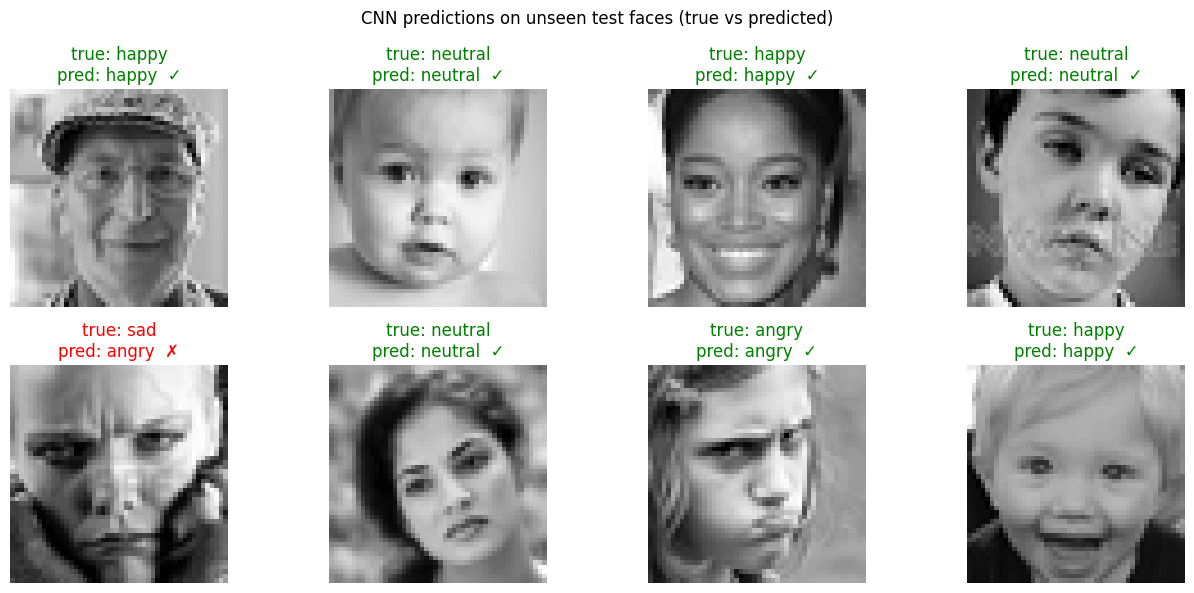

In [21]:
# --- Section 9: Predict on 8 unseen FER+ test faces ---
import random
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for ax in axes.ravel():
    i = random.randrange(len(X_test))
    face48 = X_test[i].astype('float32') / 255.0
    X = face48[None, ..., None]
    proba = (cnn.predict(X, verbose=0)[0] + cnn.predict(X[:, :, ::-1, :], verbose=0)[0]) / 2   # TTA
    pred = TARGET_CLASSES[int(proba.argmax())]
    true = TARGET_CLASSES[y_test[i]]
    ok = (pred == true)
    ax.imshow(face48, cmap='gray'); ax.axis('off')
    ax.set_title(f"true: {true}\npred: {pred}  {'✓' if ok else '✗'}",
                 color='green' if ok else 'red')
plt.suptitle("CNN predictions on unseen test faces (true vs predicted)")
plt.tight_layout(); plt.show()